In [ ]:
# Check current directory
pwd

# Should show: C:\Users\HP\elemental-society-analysis

# List files to confirm venv exists
ls

# You should see venv/ in the list
#first navigate to your folder 
cd C:\Users\HP\elemental-society-analysis
#How to activate the environment 
.\venv\Scripts\Activate.ps1

In [ ]:
#geochemical closure 


In [1]:
import pandas as pd
import chardet

# Detect encoding
with open('Major elements all.xlsx', 'rb') as f:
    result = chardet.detect(f.read())
    print(f"Detected encoding: {result['encoding']}")

# Read with detected encoding
df = pd.read_csv('Major elements all.xlsx', encoding=result['encoding'])
print(df)

ModuleNotFoundError: No module named 'chardet'

REAL PROCESS-DRIVEN PAIRS: true (absolute) vs closed (wt%) vs clr
Pair                  True r    Closed r     clr r
SiO2-MgO              -0.632      -0.832    -0.681
Al2O3-MgO             -0.644      -0.721    -0.763
CaO-MgO                0.007      -0.102    -0.246
SiO2-Al2O3             0.502       0.509     0.554

NULL MODEL: independent random 'elements' with NO real relationship
Correlation before closure (should be ~0): 0.001
Correlation AFTER closure (D=5 parts):     -0.239
Chayes theoretical expectation -1/(D-1):    -0.250


FileNotFoundError: [Errno 2] No such file or directory: '/home/claude/fig1_closure_distortion.png'

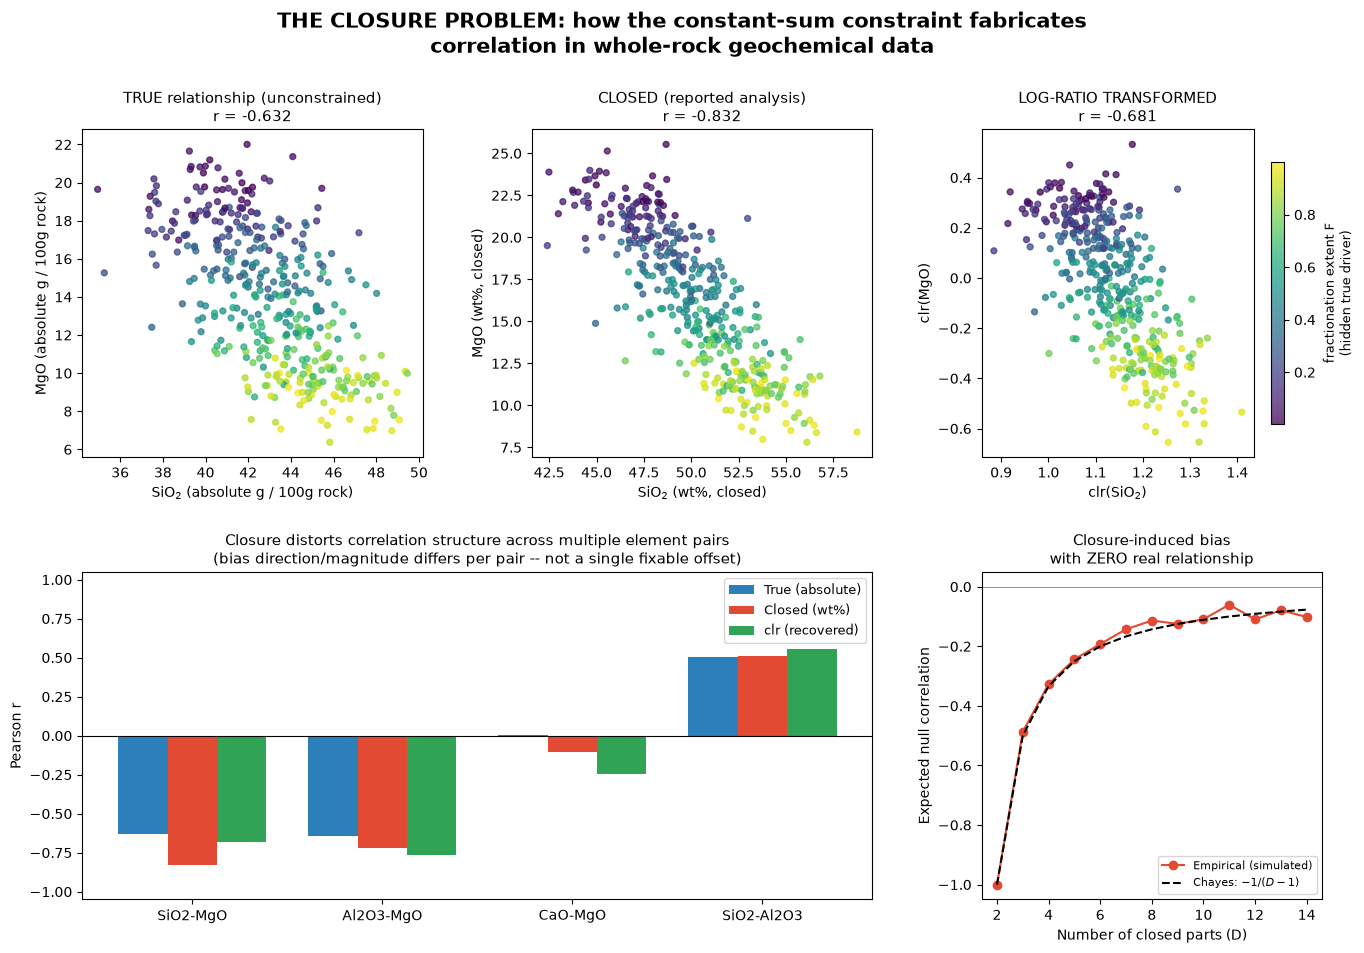

In [4]:
"""
THE CLOSURE PROBLEM IN WHOLE-ROCK GEOCHEMISTRY
================================================
Demonstrates how the constant-sum constraint (closure) inherent to
compositional data (wt%, ppm) distorts correlation structure, creating
"spurious" correlations that look like real petrogenetic signal but are
purely mathematical artifacts of the simplex geometry -- and how
log-ratio transforms (Aitchison, 1986) recover the true relationships.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, dirichlet
import matplotlib.gridspec as gridspec

np.random.seed(7)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'

# ============================================================
# PART 1 -- BUILD A REALISTIC MAGMA SUITE WITH A KNOWN PROCESS
# ============================================================
# We simulate ABSOLUTE abundances (g per 100g rock, i.e. before closure)
# for a suite of basaltic-to-andesitic rocks undergoing fractional
# crystallization of olivine + plagioclase. This creates a REAL,
# process-driven negative correlation between MgO and SiO2/Al2O3
# behavior in absolute terms -- something we can compare against
# after closure.

n = 400

# "Extent of fractionation" -- a hidden driving variable (0 = primitive, 1 = evolved)
F = np.random.uniform(0, 1, n)

# Absolute abundances, each with its own independent process + noise.
# MgO absolute mass drops as fractionation increases (olivine removal)
MgO_abs = 20 - 12 * F + np.random.normal(0, 1.2, n)
# Al2O3 absolute mass tracks plagioclase accumulation/removal -- weak, real, POSITIVE trend
Al2O3_abs = 8 + 3 * F + np.random.normal(0, 1.0, n)
# SiO2 absolute abundance -- broadly independent driver (residual melt silica build-up)
SiO2_abs = 40 + 6 * F + np.random.normal(0, 2.0, n)
# CaO -- independent of F almost entirely (decoupled real process), pure noise
CaO_abs = np.random.normal(10, 1.5, n)
# FeO -- weak real process, roughly flat
FeO_abs = 9 + 1 * F + np.random.normal(0, 1.0, n)

for arr in (MgO_abs, Al2O3_abs, SiO2_abs, CaO_abs, FeO_abs):
    np.clip(arr, 0.5, None, out=arr)

df_abs = pd.DataFrame({
    'SiO2': SiO2_abs, 'Al2O3': Al2O3_abs, 'FeO': FeO_abs,
    'MgO': MgO_abs, 'CaO': CaO_abs
})

# TRUE relationships (absolute, unconstrained abundances)
true_corrs = {}
pairs = [('SiO2', 'MgO'), ('Al2O3', 'MgO'), ('CaO', 'MgO'), ('SiO2', 'Al2O3')]
for a, b in pairs:
    r, _ = pearsonr(df_abs[a], df_abs[b])
    true_corrs[(a, b)] = r

# ============================================================
# PART 2 -- APPLY CLOSURE (this is what analytical labs report)
# ============================================================
total = df_abs.sum(axis=1)
df_closed = df_abs.div(total, axis=0) * 100  # wt%, each row sums to 100

closed_corrs = {}
for a, b in pairs:
    r, _ = pearsonr(df_closed[a], df_closed[b])
    closed_corrs[(a, b)] = r

# ============================================================
# PART 3 -- LOG-RATIO TRANSFORM (Aitchison clr) -- undo closure
# ============================================================
# Centered log-ratio: log(x_i / geometric_mean(x))
gmean = np.exp(np.log(df_closed).mean(axis=1))
df_clr = np.log(df_closed.div(gmean, axis=0))

clr_corrs = {}
for a, b in pairs:
    r, _ = pearsonr(df_clr[a], df_clr[b])
    clr_corrs[(a, b)] = r

# ============================================================
# PART 4 -- THE NULL MODEL: PURE RANDOM DATA, CLOSED
# ============================================================
# Chayes/Pearson's point in its purest form: take variables that are
# by construction totally independent (no geological process at all),
# close them, and watch a "correlation" appear out of nowhere.
n_null = 2000
D = 5  # number of "elements"
raw_random = np.random.exponential(scale=1.0, size=(n_null, D))  # independent
raw_random_df = pd.DataFrame(raw_random, columns=[f'E{i+1}' for i in range(D)])

r_indep, _ = pearsonr(raw_random_df['E1'], raw_random_df['E2'])

closed_random = raw_random_df.div(raw_random_df.sum(axis=1), axis=0) * 100
r_closed_null, _ = pearsonr(closed_random['E1'], closed_random['E2'])

# Chayes' theoretical expected null correlation for D equal-variance,
# independent parts closed to a constant sum: E[r] ~ -1/(D-1)
chayes_expected = -1 / (D - 1)

# Sweep D to show how the null bias changes with number of parts
D_values = np.arange(2, 15)
empirical_null_r = []
for Dv in D_values:
    raw = np.random.exponential(scale=1.0, size=(3000, Dv))
    closed = raw / raw.sum(axis=1, keepdims=True)
    r, _ = pearsonr(closed[:, 0], closed[:, 1])
    empirical_null_r.append(r)
theoretical_null_r = -1 / (D_values - 1)

# ============================================================
# PRINT SUMMARY
# ============================================================
print("="*70)
print("REAL PROCESS-DRIVEN PAIRS: true (absolute) vs closed (wt%) vs clr")
print("="*70)
print(f"{'Pair':<18}{'True r':>10}{'Closed r':>12}{'clr r':>10}")
for a, b in pairs:
    print(f"{a+'-'+b:<18}{true_corrs[(a,b)]:>10.3f}{closed_corrs[(a,b)]:>12.3f}{clr_corrs[(a,b)]:>10.3f}")

print("\n" + "="*70)
print("NULL MODEL: independent random 'elements' with NO real relationship")
print("="*70)
print(f"Correlation before closure (should be ~0): {r_indep:.3f}")
print(f"Correlation AFTER closure (D={D} parts):     {r_closed_null:.3f}")
print(f"Chayes theoretical expectation -1/(D-1):    {chayes_expected:.3f}")

# ============================================================
# FIGURE 1: The core distortion -- true vs closed vs clr-recovered
# ============================================================
fig = plt.figure(figsize=(16, 10))
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.35, wspace=0.32)

# (a) Absolute (unconstrained) SiO2-MgO relationship — the "truth"
ax1 = fig.add_subplot(gs[0, 0])
ax1.scatter(df_abs['SiO2'], df_abs['MgO'], c=F, cmap='viridis', s=18, alpha=0.75)
ax1.set_xlabel('SiO$_2$ (absolute g / 100g rock)')
ax1.set_ylabel('MgO (absolute g / 100g rock)')
ax1.set_title(f"TRUE relationship (unconstrained)\nr = {true_corrs[('SiO2','MgO')]:.3f}", fontsize=11)

# (b) Closed wt% — the actual reported analysis
ax2 = fig.add_subplot(gs[0, 1])
ax2.scatter(df_closed['SiO2'], df_closed['MgO'], c=F, cmap='viridis', s=18, alpha=0.75)
ax2.set_xlabel('SiO$_2$ (wt%, closed)')
ax2.set_ylabel('MgO (wt%, closed)')
ax2.set_title(f"CLOSED (reported analysis)\nr = {closed_corrs[('SiO2','MgO')]:.3f}", fontsize=11)

# (c) clr-transformed — recovered structure
ax3 = fig.add_subplot(gs[0, 2])
sc = ax3.scatter(df_clr['SiO2'], df_clr['MgO'], c=F, cmap='viridis', s=18, alpha=0.75)
ax3.set_xlabel('clr(SiO$_2$)')
ax3.set_ylabel('clr(MgO)')
ax3.set_title(f"LOG-RATIO TRANSFORMED\nr = {clr_corrs[('SiO2','MgO')]:.3f}", fontsize=11)
cb = plt.colorbar(sc, ax=ax3, shrink=0.8)
cb.set_label('fractionation extent F\n(hidden true driver)', fontsize=9)

# (d) Bar comparison across all 4 pairs
ax4 = fig.add_subplot(gs[1, :2])
labels = [f"{a}-{b}" for a, b in pairs]
x = np.arange(len(pairs))
width = 0.26
ax4.bar(x - width, [true_corrs[p] for p in pairs], width, label='True (absolute)', color='#2c7fb8')
ax4.bar(x, [closed_corrs[p] for p in pairs], width, label='Closed (wt%)', color='#e34a33')
ax4.bar(x + width, [clr_corrs[p] for p in pairs], width, label='clr (recovered)', color='#31a354')
ax4.axhline(0, color='black', lw=0.8)
ax4.set_xticks(x)
ax4.set_xticklabels(labels)
ax4.set_ylabel('Pearson r')
ax4.set_title('Closure distorts correlation structure across multiple element pairs\n(bias direction/magnitude differs per pair -- not a single fixable offset)', fontsize=11)
ax4.legend(fontsize=9)
ax4.set_ylim(-1.05, 1.05)

# (e) Null-model sweep: bias vs number of parts D
ax5 = fig.add_subplot(gs[1, 2])
ax5.plot(D_values, empirical_null_r, 'o-', color='#e34a33', label='Empirical (simulated)')
ax5.plot(D_values, theoretical_null_r, '--', color='black', label=r'Chayes: $-1/(D-1)$')
ax5.axhline(0, color='gray', lw=0.6)
ax5.set_xlabel('Number of closed parts (D)')
ax5.set_ylabel('Expected null correlation')
ax5.set_title('Closure-induced bias\nwith ZERO real relationship', fontsize=11)
ax5.legend(fontsize=8)

fig.suptitle('THE CLOSURE PROBLEM: how the constant-sum constraint fabricates\ncorrelation in whole-rock geochemical data',
             fontsize=15, fontweight='bold', y=1.00)
plt.savefig('/home/claude/fig1_closure_distortion.png', dpi=200, bbox_inches='tight')
plt.close()

# ============================================================
# FIGURE 2: Pure-noise simplex — spurious correlation from nothing
# ============================================================
fig2 = plt.figure(figsize=(15, 5.5))

# (a) 3-part Dirichlet random composition on the simplex (3D view)
ax1 = fig2.add_subplot(131, projection='3d')
rand3 = dirichlet.rvs([1, 1, 1], size=1200, random_state=3) * 100
ax1.scatter(rand3[:, 0], rand3[:, 1], rand3[:, 2], c=rand3[:, 2], cmap='plasma', s=8, alpha=0.6)
ax1.set_xlabel('A (%)'); ax1.set_ylabel('B (%)'); ax1.set_zlabel('C (%)')
ax1.set_title('Pure random composition\n(uniform on simplex, zero geology)', fontsize=11)
ax1.view_init(elev=25, azim=45)

# (b) 2D projection A vs B -- looks like a real negative trend!
ax2 = fig2.add_subplot(132)
r3, _ = pearsonr(rand3[:, 0], rand3[:, 1])
ax2.scatter(rand3[:, 0], rand3[:, 1], c=rand3[:, 2], cmap='plasma', s=10, alpha=0.6)
ax2.set_xlabel('A (%)'); ax2.set_ylabel('B (%)')
ax2.set_title(f'A vs B, r = {r3:.3f}\n"looks like" a real inverse trend\n(100% closure artifact)', fontsize=11)

# (c) distribution of null-correlation across many random simplex draws (D=3)
ax3 = fig2.add_subplot(133)
null_r_dist = []
for _ in range(500):
    s = dirichlet.rvs([1, 1, 1], size=300)
    r, _ = pearsonr(s[:, 0], s[:, 1])
    null_r_dist.append(r)
ax3.hist(null_r_dist, bins=30, color='#756bb1', edgecolor='white')
ax3.axvline(np.mean(null_r_dist), color='red', linestyle='--',
            label=f"mean r = {np.mean(null_r_dist):.2f}")
ax3.axvline(0, color='black', lw=0.8)
ax3.set_xlabel('Pearson r (A vs B)')
ax3.set_ylabel('count (500 random simplex samples)')
ax3.set_title('Null correlation is not noise around 0 --\nit is SYSTEMATICALLY negative (D=3)', fontsize=10.5)
ax3.legend(fontsize=9)

fig2.suptitle('Spurious correlation from CLOSURE ALONE: no geological process involved',
              fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig('/home/claude/fig2_pure_noise_simplex.png', dpi=200, bbox_inches='tight')
plt.close()

print("\nSaved: fig1_closure_distortion.png, fig2_pure_noise_simplex.png")

In [3]:
import os
os.makedirs('outputs', exist_ok=True)  # create it if it doesn't exist

plt.savefig('outputs/fig1_closure_distortion.png', dpi=200, bbox_inches='tight')
...
plt.savefig('outputs/fig2_pure_noise_simplex.png', dpi=200, bbox_inches='tight')

<Figure size 640x480 with 0 Axes>